# HA2C training costs: Agent 1, Agent 2, and total

This notebook finds the training `.npz` file in each **128 CN**, **256 CN**, and **512 CN** folder under `Higher Nodes- LR 2`, loads the two agent-cost histories, computes their **elementwise sum**, and plots all three histories. Each CN gets an individual IEEE-style figure; a three-panel comparison is also saved.

**Before running:** edit `ROOT_DIR` below if needed. Run cells in order. The notebook prints the available `.npz` keys and detected cost keys so you can verify the arrays before plotting; if automatic detection is ambiguous, set `COST_KEYS` explicitly. It does **not** add final cumulative totals or average costs: the total at index `i` is `Agent 1[i] + Agent 2[i]`.

Required libraries: `numpy`, `matplotlib`, `pandas` (optional for the preview table; this notebook uses `pandas`).

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Point this to the folder containing "128 CN", "256 CN", and "512 CN".
# If the notebook itself is saved inside "Higher Nodes- LR 2", Path.cwd() is sufficient.
ROOT_DIR = Path.cwd()  # Or e.g.: Path("/home/cci/Downloads/Latest/Revised/Higher Nodes- LR 2")

CN_VALUES = (128, 256, 512)
NPZ_GLOB = "*.npz"  # Narrow to "ha2c_training_results*.npz" if necessary.

# Optional explicit mapping when the arrays do not use recognizable names:
# COST_KEYS = {128: ("all_cost1", "all_cost2"), 256: (...), 512: (...)}
COST_KEYS = {}  # Unspecified folders are auto-detected.

# Indices on the x-axis are 0, 1, ..., N-1. Change to 1 for one-based numbering.
X_START = 0
X_LABEL = "Training step"  # Set to "Episode" if each array entry is an episode.
MARK_EVERY = 200

OUTPUT_DIR_NAME = "cost_plots"
SAVE_PNG = True
SAVE_PDF = True

# Convenience: find a child root if the notebook is run one directory above it.
if not all((ROOT_DIR / f"{cn} CN").is_dir() for cn in CN_VALUES):
    options = [p for p in ROOT_DIR.iterdir() if p.is_dir() and "higher nodes" in p.name.lower()]
    matches = [p for p in options if all((p / f"{cn} CN").is_dir() for cn in CN_VALUES)]
    if len(matches) == 1:
        ROOT_DIR = matches[0]

ROOT_DIR = ROOT_DIR.expanduser().resolve()
missing = [f"{cn} CN" for cn in CN_VALUES if not (ROOT_DIR / f"{cn} CN").is_dir()]
if missing:
    raise FileNotFoundError(
        f"Missing folders under {ROOT_DIR}: {missing}. Edit ROOT_DIR to the directory "
        'containing "128 CN", "256 CN", and "512 CN".'
    )

OUTPUT_DIR = ROOT_DIR / OUTPUT_DIR_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Data root:", ROOT_DIR)
print("Figures will be saved to:", OUTPUT_DIR)

Data root: /home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2
Figures will be saved to: /home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2/cost_plots


## 1. Find the NPZ file in each CN folder

The notebook prefers filenames containing `ha2c` and `training` when there are multiple `.npz` files. If more than one still matches, it stops and asks you to choose a file rather than silently taking an arbitrary run.

In [2]:
# Optional: specify an exact file when a CN folder contains multiple training runs.
# Example: NPZ_FILES = {128: ROOT_DIR / "128 CN" / "ha2c_training_results_128_nodes_lr_0_00001.npz"}
NPZ_FILES = {}


def find_npz_file(cn):
    if cn in NPZ_FILES:
        path = Path(NPZ_FILES[cn]).expanduser().resolve()
        if not path.is_file():
            raise FileNotFoundError(f"CN={cn}: specified file does not exist: {path}")
        return path

    directory = ROOT_DIR / f"{cn} CN"
    candidates = sorted(p for p in directory.glob(NPZ_GLOB) if p.is_file())
    if not candidates:
        raise FileNotFoundError(f"No NPZ files found in {directory}")
    if len(candidates) == 1:
        return candidates[0]

    preferred = [p for p in candidates if "ha2c" in p.name.lower() and "training" in p.name.lower()]
    if len(preferred) == 1:
        return preferred[0]
    remaining = preferred if preferred else candidates
    raise ValueError(
        f"CN={cn}: multiple possible NPZ files: {[p.name for p in remaining]}. "
        "Set NPZ_FILES[cn] to the exact file you want to plot."
    )

npz_paths = {cn: find_npz_file(cn) for cn in CN_VALUES}
for cn, path in npz_paths.items():
    print(f"{cn} CN -> {path}")

128 CN -> /home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2/128 CN/ha2c_training_results_128 nodes_lr_0_00001.npz
256 CN -> /home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2/256 CN/ha2c_training_results_256 nodes_lr_0_00001.npz
512 CN -> /home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2/512 CN/ha2c_training_results_512 nodes_lr_0_00001.npz


## 2. Inspect NPZ keys and load cost histories

Candidate names include `all_cost1` / `all_cost2`, `agent1_cost` / `agent2_cost`, and other variants. If your file uses different names, the printed key list will help you fill in `COST_KEYS` in the configuration cell and rerun. Object/pickled data are deliberately not loaded automatically.

In [3]:
AGENT_1_ALIASES = (
    "all_cost1", "all_cost_1", "all_cost_agent1", "all_cost_agent_1",
    "agent1_cost", "agent_1_cost", "agent1_costs", "agent_1_costs",
    "cost_agent1", "cost_agent_1", "cost1", "cost_1",
    "agent1_placement_cost", "agent_1_placement_cost",
)
AGENT_2_ALIASES = (
    "all_cost2", "all_cost_2", "all_cost_agent2", "all_cost_agent_2",
    "agent2_cost", "agent_2_cost", "agent2_costs", "agent_2_costs",
    "cost_agent2", "cost_agent_2", "cost2", "cost_2",
    "agent2_placement_cost", "agent_2_placement_cost",
)


def normalized_key(name):
    return re.sub(r"[^a-z0-9]", "", name.lower())


def choose_cost_key(names, aliases, agent_number):
    by_normalized = {}
    for name in names:
        by_normalized.setdefault(normalized_key(name), []).append(name)
    for alias in aliases:
        matches = by_normalized.get(normalized_key(alias), [])
        if len(matches) == 1:
            return matches[0]
        if len(matches) > 1:
            raise ValueError(f"Ambiguous keys {matches}; set COST_KEYS explicitly.")

    # Flexible fallback for names such as "training_agent_1_cost_history".
    pattern = re.compile(rf"(?:agent[_\- ]?{agent_number}|costs?[_\- ]?{agent_number}|costs?agent[_\- ]?{agent_number})", re.I)
    candidates = [name for name in names if "cost" in name.lower() and pattern.search(name)]
    if len(candidates) == 1:
        return candidates[0]
    raise ValueError(
        f"Unable to select exactly one Agent {agent_number} cost key from {list(names)}. "
        'Set COST_KEYS[CN] = ("agent_1_key", "agent_2_key") in the configuration cell.'
    )


def as_cost_history(raw, cn, key):
    try:
        values = np.asarray(raw, dtype=float)
    except (TypeError, ValueError) as exc:
        raise ValueError(
            f"CN={cn}, key={key!r}: expected a numeric cost array, got a nonnumeric "
            "or object-based value. Inspect how this NPZ was saved."
        ) from exc
    if values.ndim == 2 and 1 in values.shape:
        values = values.reshape(-1)
    if values.ndim != 1 or values.size == 0:
        raise ValueError(
            f"CN={cn}, key={key!r}: expected a nonempty 1-D history; got shape {values.shape}. "
            "Check whether the array contains episodes, multiple runs, or another metric."
        )
    if not np.isfinite(values).all():
        raise ValueError(f"CN={cn}, key={key!r}: history contains NaN/Inf values.")
    return values


history = {}
for cn, path in npz_paths.items():
    with np.load(path, allow_pickle=False) as data:
        names = list(data.files)
        print(f"\n{cn} CN NPZ keys: {names}")
        if cn in COST_KEYS:
            key1, key2 = COST_KEYS[cn]
            if key1 not in names or key2 not in names:
                raise KeyError(f"CN={cn}: specified COST_KEYS {COST_KEYS[cn]} missing from {names}")
        else:
            key1 = choose_cost_key(names, AGENT_1_ALIASES, 1)
            key2 = choose_cost_key(names, AGENT_2_ALIASES, 2)
        if key1 == key2:
            raise ValueError(f"CN={cn}: Agent 1 and Agent 2 keys must differ.")
        agent1 = as_cost_history(data[key1], cn, key1)
        agent2 = as_cost_history(data[key2], cn, key2)

    if agent1.shape != agent2.shape:
        raise ValueError(
            f"CN={cn}: agent histories must align elementwise, but "
            f"{key1} has {len(agent1)} values and {key2} has {len(agent2)}."
        )
    total = agent1 + agent2
    if not np.isfinite(total).all():
        raise ValueError(f"CN={cn}: Agent 1 + Agent 2 produced NaN/Inf values.")
    history[cn] = {
        "steps": np.arange(X_START, X_START + len(agent1)),
        "agent1": agent1,
        "agent2": agent2,
        "total": total,
        "keys": (key1, key2),
    }
    print(f"Using {key1!r} + {key2!r}; number of observations: {len(agent1):,}")

preview = pd.DataFrame(
    [{"CNs": cn, "Agent 1 key": h["keys"][0], "Agent 2 key": h["keys"][1],
      "Observations": len(h["agent1"]), "Last Agent 1 cost": h["agent1"][-1],
      "Last Agent 2 cost": h["agent2"][-1], "Last total cost": h["total"][-1]}
     for cn, h in history.items()]
)
display(preview)


128 CN NPZ keys: ['agent1_cost', 'agent1_reward', 'agent1_actor_loss_lr_0_000001', 'agent1_critic_loss', 'agent2_cost', 'agent2_reward', 'agent2_actor_loss_lr_0_000001', 'agent2_critic_loss', 'agent1_selected_nodes', 'agent2_selected_nodes', 'e2_to_g1_association', 'g1_to_g2_association', 'e2_nodes', 'active_g1_nodes', 'latency_matrix']
Using 'agent1_cost' + 'agent2_cost'; number of observations: 3,000

256 CN NPZ keys: ['agent1_cost', 'agent1_reward', 'agent1_actor_loss_lr_0_000001', 'agent1_critic_loss', 'agent2_cost', 'agent2_reward', 'agent2_actor_loss_lr_0_000001', 'agent2_critic_loss', 'agent1_selected_nodes', 'agent2_selected_nodes', 'e2_to_g1_association', 'g1_to_g2_association', 'e2_nodes', 'active_g1_nodes', 'latency_matrix']
Using 'agent1_cost' + 'agent2_cost'; number of observations: 3,000

512 CN NPZ keys: ['agent1_cost', 'agent1_reward', 'agent1_actor_loss_lr_0_000001', 'agent1_critic_loss', 'agent2_cost', 'agent2_reward', 'agent2_actor_loss_lr_0_000001', 'agent2_critic_

,CNs,Agent 1 key,Agent 2 key,Observations,Last Agent 1 cost,Last Agent 2 cost,Last total cost
0,128,agent1_cost,agent2_cost,3000,110.0,36.0,146.0
1,256,agent1_cost,agent2_cost,3000,210.0,68.0,278.0
2,512,agent1_cost,agent2_cost,3000,470.0,148.0,618.0


## 3. IEEE-style line plot settings

Agent 1 = **navy squares**, Agent 2 = **green circles**, Total = **yellow triangles**. The yellow curve is outlined with black markers for readability on a white page.

In [4]:
plt.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.size": 12,
    "axes.labelsize": 18,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
    "axes.linewidth": 1.2,
    "lines.linewidth": 2.0,
    "grid.linewidth": 0.8,
    "savefig.dpi": 600,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

CURVE_STYLES = {
    "agent1": dict(label="Agent 1", color="navy", marker="s"),
    "agent2": dict(label="Agent 2", color="green", marker="o"),
    "total": dict(label="Total cost (Agent 1 + Agent 2)", color="#E6B800", marker="^"),
}


def draw_cost_curves(ax, h):
    for metric, style in CURVE_STYLES.items():
        ax.plot(
            h["steps"], h[metric],
            label=style["label"],
            color=style["color"],
            linestyle="-",
            linewidth=1.8,
            marker=style["marker"],
            markersize=4,
            markevery=MARK_EVERY,
            markerfacecolor="white",
            markeredgewidth=1.2,
        )
    ax.set_xlabel(X_LABEL)
    ax.set_ylabel("Placement cost")
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.tick_params(direction="in", top=True, right=True)


def save_figure(fig, stem):
    if SAVE_PNG:
        path = OUTPUT_DIR / f"{stem}.png"
        fig.savefig(path, dpi=600, bbox_inches="tight")
        print("Saved:", path)
    if SAVE_PDF:
        path = OUTPUT_DIR / f"{stem}.pdf"
        fig.savefig(path, bbox_inches="tight")
        print("Saved:", path)

## 4. Plot and save one figure per CN

Saved: /home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2/cost_plots/ha2c_agent_costs_128_CN.png
Saved: /home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2/cost_plots/ha2c_agent_costs_128_CN.pdf


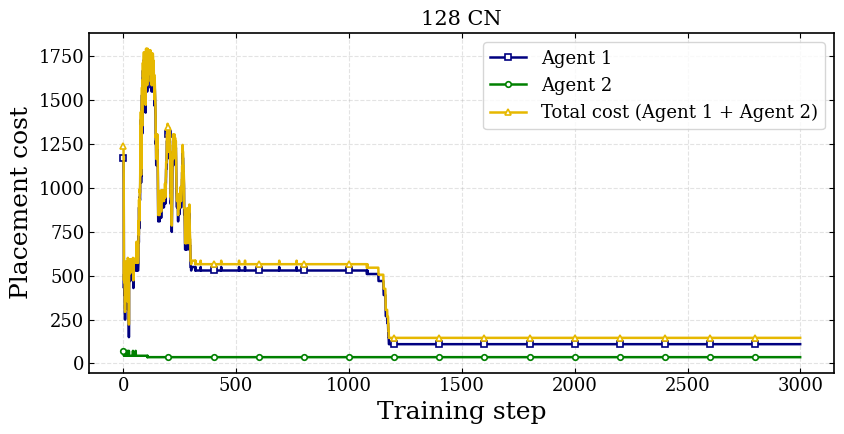

Saved: /home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2/cost_plots/ha2c_agent_costs_256_CN.png
Saved: /home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2/cost_plots/ha2c_agent_costs_256_CN.pdf


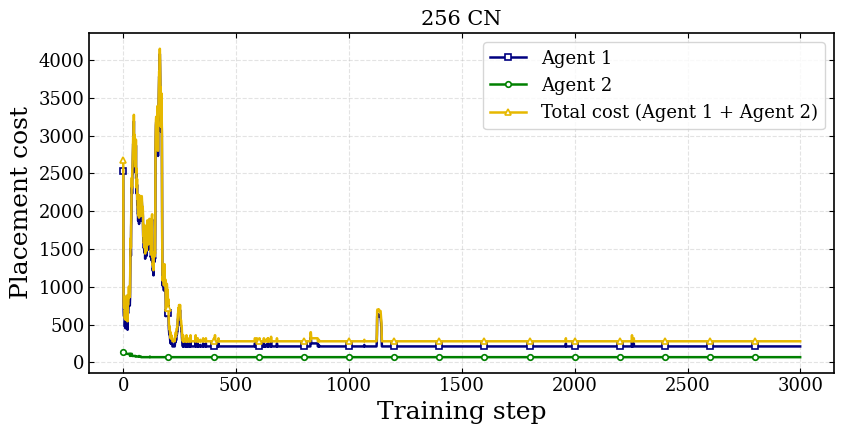

Saved: /home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2/cost_plots/ha2c_agent_costs_512_CN.png
Saved: /home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2/cost_plots/ha2c_agent_costs_512_CN.pdf


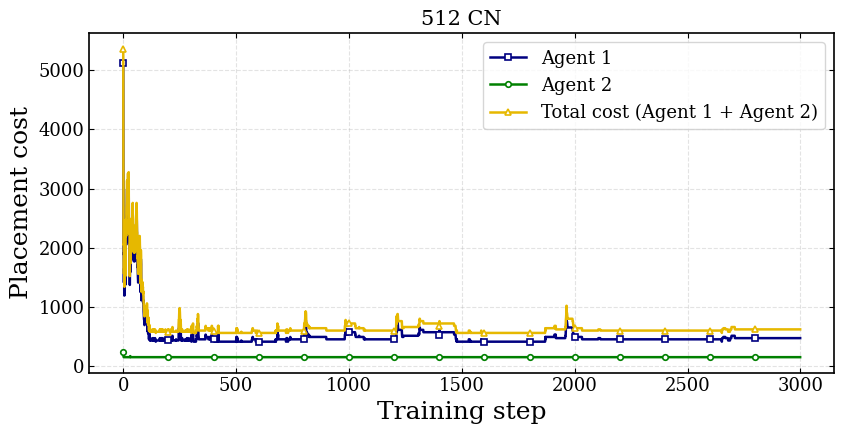

In [5]:
for cn, h in history.items():
    fig, ax = plt.subplots(figsize=(8.6, 4.5))
    draw_cost_curves(ax, h)
    ax.set_title(f"{cn} CN", fontsize=15)
    ax.legend(loc="best", frameon=True)
    fig.tight_layout()
    save_figure(fig, f"ha2c_agent_costs_{cn}_CN")
    plt.show()
    plt.close(fig)

## 5. Optional: combined 128 / 256 / 512 CN figure

Three panels use separate x-axes because training histories may have different lengths. The legend and line styles are consistent across panels.

Saved: /home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2/cost_plots/ha2c_agent_costs_all_CN.png
Saved: /home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2/cost_plots/ha2c_agent_costs_all_CN.pdf


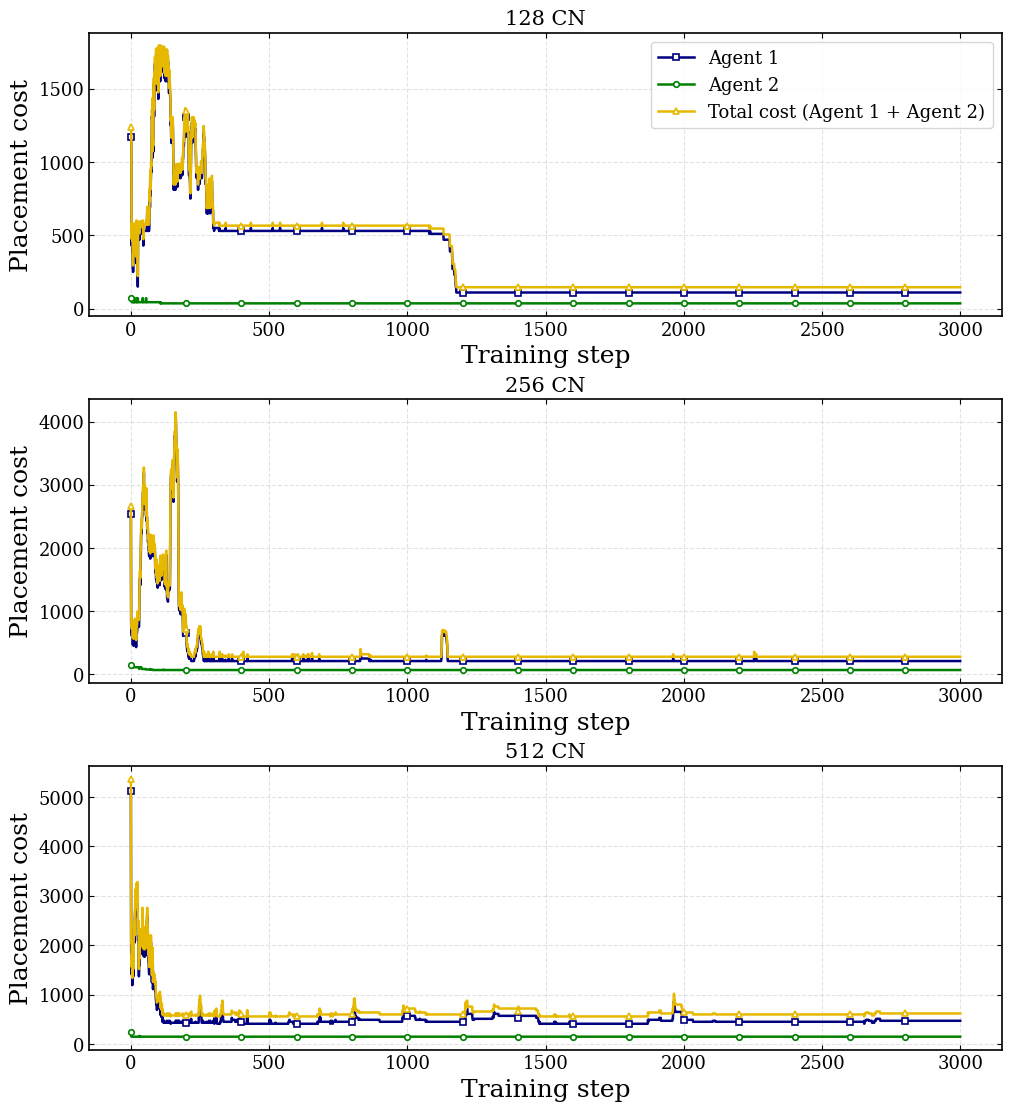

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(10, 11), constrained_layout=True)
for ax, cn in zip(axes, CN_VALUES):
    draw_cost_curves(ax, history[cn])
    ax.set_title(f"{cn} CN", fontsize=15)
axes[0].legend(loc="best", frameon=True)
save_figure(fig, "ha2c_agent_costs_all_CN")
plt.show()
plt.close(fig)


Loading 128 CN:
/home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2/128 CN/ha2c_training_results_128 nodes_lr_0_00001.npz
Available NPZ keys: ['agent1_cost', 'agent1_reward', 'agent1_actor_loss_lr_0_000001', 'agent1_critic_loss', 'agent2_cost', 'agent2_reward', 'agent2_actor_loss_lr_0_000001', 'agent2_critic_loss', 'agent1_selected_nodes', 'agent2_selected_nodes', 'e2_to_g1_association', 'g1_to_g2_association', 'e2_nodes', 'active_g1_nodes', 'latency_matrix']
Training steps: 3000

Loading 256 CN:
/home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2/256 CN/ha2c_training_results_256 nodes_lr_0_00001.npz
Available NPZ keys: ['agent1_cost', 'agent1_reward', 'agent1_actor_loss_lr_0_000001', 'agent1_critic_loss', 'agent2_cost', 'agent2_reward', 'agent2_actor_loss_lr_0_000001', 'agent2_critic_loss', 'agent1_selected_nodes', 'agent2_selected_nodes', 'e2_to_g1_association', 'g1_to_g2_association', 'e2_nodes', 'active_g1_nodes', 'latency_matrix']
Training steps: 3000

Loading 512 CN:
/home

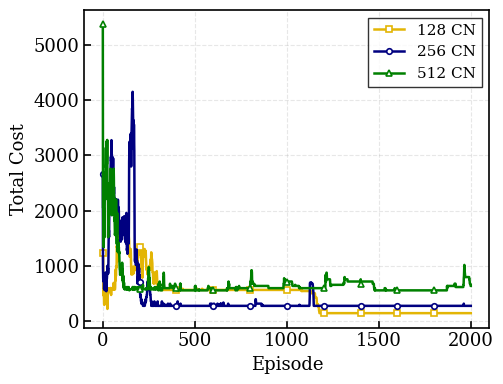


Figures saved successfully:
/home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2/HA2C_Total_Cost_128_256_512_CN.png
/home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2/HA2C_Total_Cost_128_256_512_CN.pdf


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. Root directory containing the three CN folders
# ============================================================

ROOT_DIR = Path(
    "/home/cci/Downloads/Latest/Revised/Higher Nodes - LR 2"
)

CN_FOLDERS = {
    128: "128 CN",
    256: "256 CN",
    512: "512 CN"
}

# ============================================================
# 2. IEEE-style plot settings
# ============================================================

plt.rcParams.update({
    'font.family': 'DejaVu Serif',
    'font.size': 12,
    'axes.labelsize': 13,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 11,
    'axes.linewidth': 1.2,
    'lines.linewidth': 2.0,
    'grid.linewidth': 0.8,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

# ============================================================
# 3. Extract Agent 1 and Agent 2 costs from NPZ files
# ============================================================

def load_total_cost(cn):

    folder = ROOT_DIR / CN_FOLDERS[cn]

    # Find the training-results NPZ file
    npz_files = sorted(folder.glob("ha2c_training_results*.npz"))

    if len(npz_files) != 1:
        raise FileNotFoundError(
            f"Expected exactly one HA2C training-results NPZ "
            f"in {folder}, found {len(npz_files)}."
        )

    npz_path = npz_files[0]

    print(f"\nLoading {cn} CN:")
    print(npz_path)

    with np.load(npz_path, allow_pickle=False) as data:

        print("Available NPZ keys:", data.files)

        # Agent cost arrays
        cost1 = np.asarray(data["agent1_cost"], dtype=float).squeeze()
        cost2 = np.asarray(data["agent2_cost"], dtype=float).squeeze()

    # Check that both cost histories are compatible
    if cost1.ndim != 1 or cost2.ndim != 1:
        raise ValueError(
            f"{cn} CN: Agent cost histories must be 1D arrays. "
            f"Received shapes {cost1.shape} and {cost2.shape}."
        )

    if cost1.shape != cost2.shape:
        raise ValueError(
            f"{cn} CN: Agent 1 and Agent 2 have different "
            f"cost-history lengths: {len(cost1)} and {len(cost2)}."
        )

    # Sum both agents' costs for every training step
    total_cost = cost1 + cost2

    print(f"Training steps: {len(total_cost)}")

    return total_cost


# ============================================================
# 4. Load the total cost for all three CN configurations
# ============================================================

total_cost_128 = load_total_cost(128)
total_cost_256 = load_total_cost(256)
total_cost_512 = load_total_cost(512)

print(total_cost_128[-1])
print(total_cost_256[-1])
print(total_cost_512[-1])


# ============================================================
# 5. Generate ONE plot containing three total-cost curves
# ============================================================

fig, ax = plt.subplots(figsize=(5.2, 4))

# -------------------------
# 128 CN - Yellow
# -------------------------

ax.plot(
    total_cost_128[0:2000],
    label='128 CN',
    color='#E3B505',
    linestyle='-',
    linewidth=1.8,
    marker='s',
    markersize=4,
    markevery=200,
    markerfacecolor='white',
    markeredgewidth=1.2
)

# -------------------------
# 256 CN - Navy
# -------------------------

ax.plot(
    total_cost_256[0:2000],
    label='256 CN',
    color='navy',
    linestyle='-',
    linewidth=1.8,
    marker='o',
    markersize=4,
    markevery=200,
    markerfacecolor='white',
    markeredgewidth=1.2
)

# -------------------------
# 512 CN - Green
# -------------------------

ax.plot(
    total_cost_512[0:2000],
    label='512 CN',
    color='green',
    linestyle='-',
    linewidth=1.8,
    marker='^',
    markersize=4,
    markevery=200,
    markerfacecolor='white',
    markeredgewidth=1.2
)

# ============================================================
# 6. Axis labels and formatting
# ============================================================

ax.set_xlabel('Episode')
ax.set_ylabel('Total Cost')

ax.set_xticks(np.arange(0, 2100, 500))

ax.legend(
    loc='best',
    frameon=True,
    edgecolor='black',
    fancybox=False
)

ax.grid(
    True,
    linestyle='--',
    alpha=0.3
)

ax.tick_params(
    axis='both',
    which='major',
    direction='in',
    length=5,
    width=1.2
)

fig.tight_layout()


# ============================================================
# 7. Save the single figure
# ============================================================

output_png = ROOT_DIR / "HA2C_Total_Cost_128_256_512_CN.png"
output_pdf = ROOT_DIR / "HA2C_Total_Cost_128_256_512_CN.pdf"

fig.savefig(
    output_png,
    dpi=600,
    bbox_inches='tight'
)

fig.savefig(
    output_pdf,
    bbox_inches='tight'
)

plt.show()

print("\nFigures saved successfully:")
print(output_png)
print(output_pdf)